In [1]:
!pip install catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 59.2 MB/s  0:00:01


/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [2]:
df = pd.read_csv('/content/House_Rent_Dataset.csv')
df

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,5/18/2022,2,15000.0,1000.0,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2.0,Contact Owner
4742,5/15/2022,3,29000.0,2000.0,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Owner
4743,7/10/2022,3,35000.0,1750.0,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Agent
4744,7/6/2022,3,45000.0,1500.0,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2.0,Contact Agent


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [4]:
df[['Rent','Size','Bathroom']] = df[['Rent','Size','Bathroom']].astype('Int64')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4741 non-null   Int64 
 3   Size               4738 non-null   Int64 
 4   Floor              4746 non-null   object
 5   Area Type          4739 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4742 non-null   Int64 
 11  Point of Contact   4746 non-null   object
dtypes: Int64(3), int64(1), object(8)
memory usage: 459.0+ KB


In [6]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4741.0,4738.0,4742.0
mean,2.083860,35023.395908,967.936049,1.965837
std,0.832256,78142.139158,634.562635,0.884904
min,1.000000,1200.0,10.0,1.0
25%,2.000000,10000.0,550.0,1.0
50%,2.000000,16000.0,850.0,2.0
75%,3.000000,33000.0,1200.0,2.0
max,6.000000,3500000.0,8000.0,10.0


In [7]:
df.isnull().sum()

,0
Posted On,0
BHK,0
Rent,5
Size,8
Floor,0
Area Type,7
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


In [8]:
df['Size'].skew()

np.float64(2.2981542396330705)

In [9]:
df['Rent'].skew()

np.float64(21.402053848072253)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,5/13/2022,2,20000,<NA>,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,5/16/2022,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,7/4/2022,2,10000,<NA>,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,5/9/2022,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [12]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan,strategy='most_frequent')
for i in ['Tenant Preferred','Area Locality','Area Type']:
  df[[i]]=imputer.fit_transform(df[[i]])

In [13]:
df.isnull().sum()

,0
Posted On,0
BHK,0
Rent,5
Size,8
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


In [14]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan,strategy='mean')

for i in ['Size','Rent']:
  df[[i]]= imputer.fit_transform(df[[i]])

In [15]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan,strategy='most_frequent')
df[['Bathroom']] = imputer.fit_transform(df[['Bathroom']])

In [16]:
df.isnull().sum()

,0
Posted On,0
BHK,0
Rent,0
Size,0
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


In [17]:
df.head(3)

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.000000,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,967.936049,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.000000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner


In [18]:
df['City'].unique()

array(['Kolkata', 'Mumbai', 'Bangalore', 'Delhi', 'Chennai', 'Hyderabad'],
      dtype=object)

<Axes: xlabel='City', ylabel='Rent'>

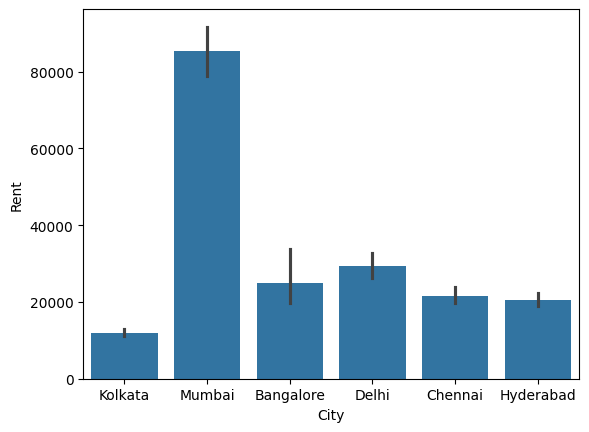

In [19]:
sns.barplot(data=df,x='City',y='Rent')


**Mumbai the highest city**

In [20]:
df['Area Locality'].nunique()

2235

<Axes: xlabel='Area Locality', ylabel='Rent'>

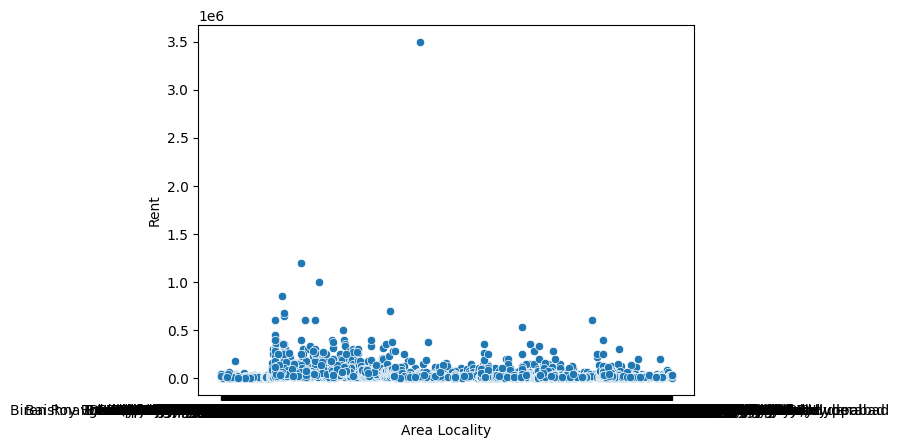

In [21]:
sns.scatterplot(data=df,x='Area Locality',y='Rent')


<Axes: xlabel='Size', ylabel='Rent'>

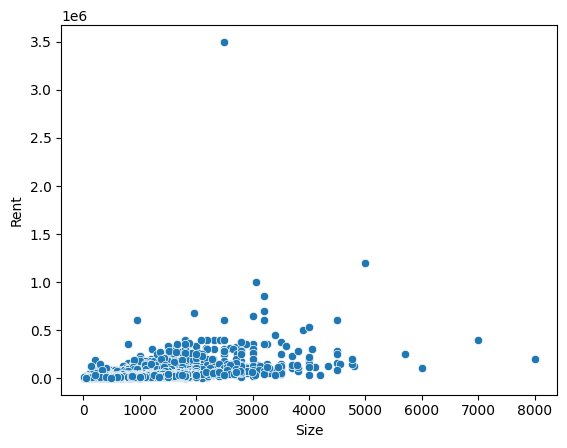

In [22]:
sns.scatterplot(data=df,x='Size',y='Rent')

<Axes: xlabel='BHK', ylabel='Rent'>

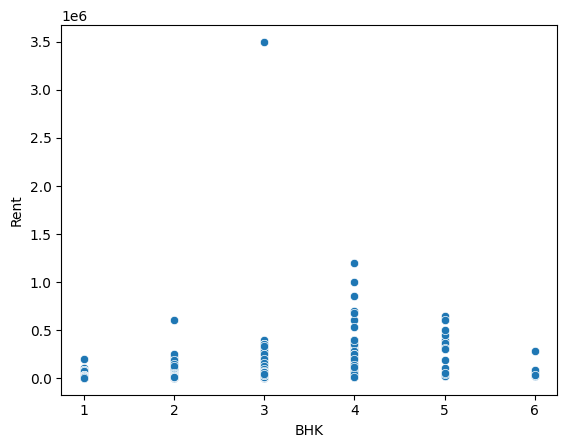

In [23]:
sns.scatterplot(data=df,x='BHK',y='Rent')

In [24]:
df.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='object')

<Axes: xlabel='Posted On', ylabel='Rent'>

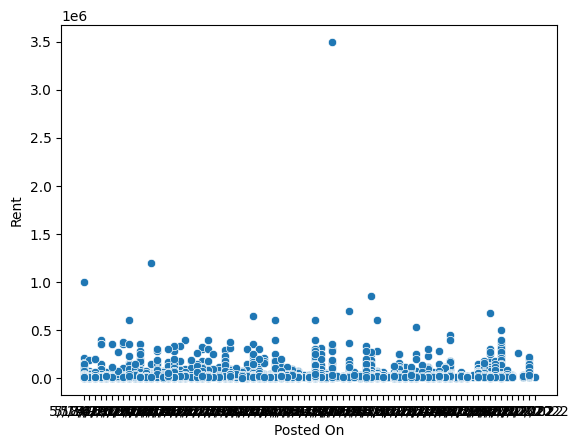

In [25]:
sns.scatterplot(data=df,x='Posted On',y='Rent')


<Axes: xlabel='Floor', ylabel='Rent'>

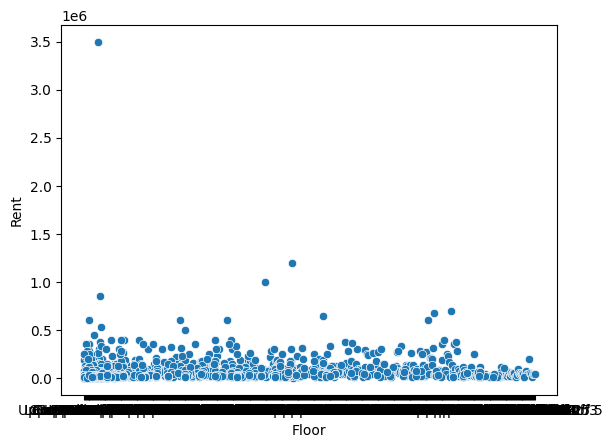

In [26]:
sns.scatterplot(data=df,x='Floor',y='Rent')


<Axes: xlabel='Tenant Preferred', ylabel='Rent'>

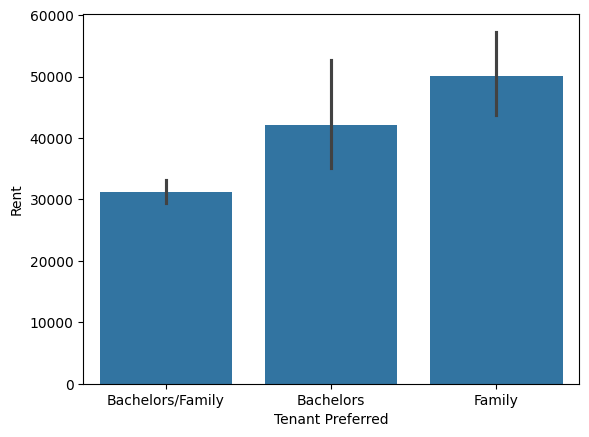

In [27]:
sns.barplot(data=df,x='Tenant Preferred',y='Rent')

<Axes: xlabel='Point of Contact', ylabel='Rent'>

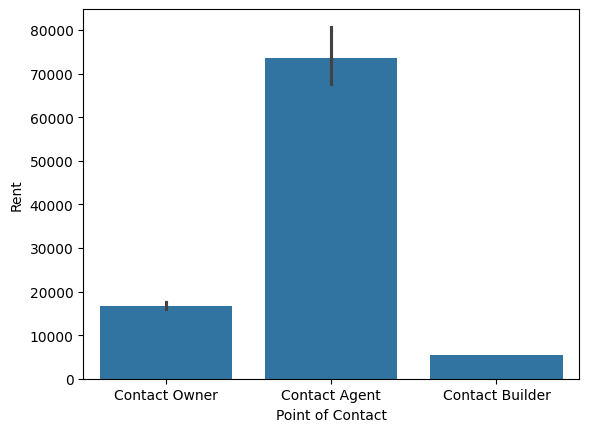

In [28]:
sns.barplot(data=df,x='Point of Contact',y='Rent')

<Axes: xlabel='Furnishing Status', ylabel='Rent'>

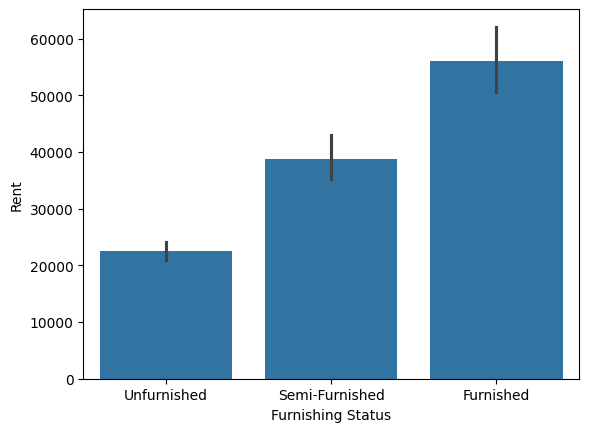

In [29]:
sns.barplot(data=df,x='Furnishing Status',y='Rent')

<Axes: xlabel='Area Type', ylabel='Rent'>

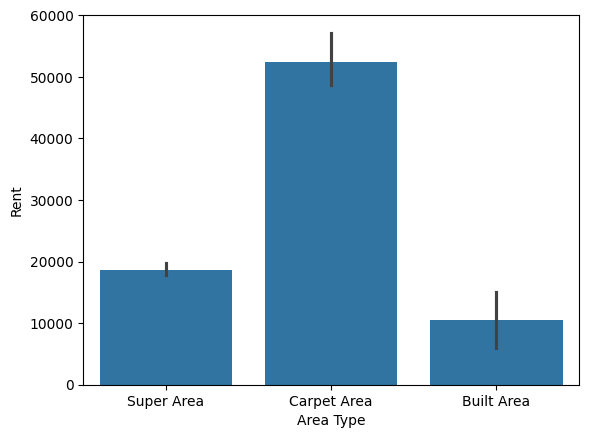

In [30]:
sns.barplot(data=df,x='Area Type',y='Rent')

<Axes: xlabel='Bathroom', ylabel='Rent'>

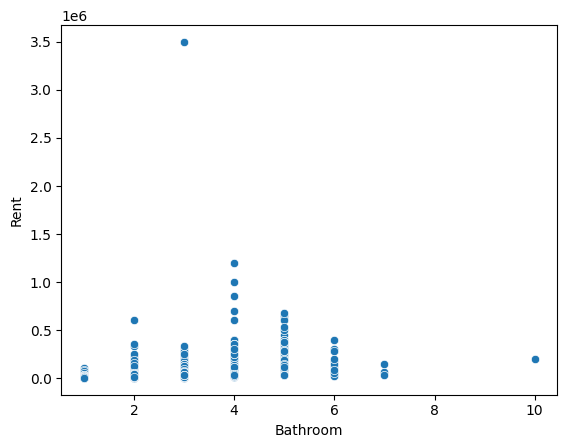

In [31]:
sns.scatterplot(data=df,x='Bathroom',y='Rent')

In [32]:
for i in df.select_dtypes('object').columns:
  print(f'{i} number of unique = ',df[i].nunique())
  print('*'*40)

Posted On number of unique =  81
****************************************
Floor number of unique =  480
****************************************
Area Type number of unique =  3
****************************************
Area Locality number of unique =  2235
****************************************
City number of unique =  6
****************************************
Furnishing Status number of unique =  3
****************************************
Tenant Preferred number of unique =  3
****************************************
Point of Contact number of unique =  3
****************************************


In [33]:
col_1 = ['Area Type','Furnishing Status','Tenant Preferred','Point of Contact']

In [34]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
for i in col_1:
  ohe_encoded = ohe.fit_transform(df[[i]]).toarray()
  ohe_df = pd.DataFrame(ohe_encoded,columns=ohe.get_feature_names_out([i]),index=df.index)
  df = pd.concat([df,ohe_df],axis=1)
  df.drop(i,axis=1,inplace=True)


In [35]:
print(ohe.categories_[0])


['Contact Agent' 'Contact Builder' 'Contact Owner']


In [36]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Locality,City,Bathroom,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,5/18/2022,2,10000.0,1100.000000,Ground out of 2,Bandel,Kolkata,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,5/13/2022,2,20000.0,967.936049,1 out of 3,"Phool Bagan, Kankurgachi",Kolkata,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,5/16/2022,2,17000.0,1000.000000,1 out of 3,Salt Lake City Sector 2,Kolkata,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,7/4/2022,2,10000.0,967.936049,1 out of 2,Dumdum Park,Kolkata,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,5/9/2022,2,7500.0,850.000000,1 out of 2,South Dum Dum,Kolkata,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [37]:
df.shape

(4746, 20)

In [38]:
df.drop(['Posted On'],axis=1,inplace=True)

In [39]:
for i in df.select_dtypes('object').columns:
  print(f'{i} number of unique = ',df[i].nunique())
  print('*'*40)

Floor number of unique =  480
****************************************
Area Locality number of unique =  2235
****************************************
City number of unique =  6
****************************************


In [40]:
from sklearn.preprocessing import LabelEncoder
lb = LabelEncoder()
df['City'] = lb.fit_transform(df['City'])

In [41]:
for i in df.select_dtypes('object').columns:
  print(f'{i} number of unique = ',df[i].nunique())
  print('*'*40)

Floor number of unique =  480
****************************************
Area Locality number of unique =  2235
****************************************


In [42]:
!pip install category-encoders
!pip install category_encoders
import category_encoders as ce

In [43]:
target_enc = ce.TargetEncoder(cols = ['Floor','Area Locality'],smoothing=5)
df[['Floor','Area Locality']] = target_enc.fit_transform(df[['Floor','Area Locality']],df['Rent'])


In [44]:
df.head()

,BHK,Rent,Size,Floor,Area Locality,City,Bathroom,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,2,10000.0,1100.000000,14394.449108,34311.304069,4,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,2,20000.0,967.936049,17954.607509,34404.393547,4,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,2,17000.0,1000.000000,17954.607509,31353.966138,4,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,2,10000.0,967.936049,14446.701847,34517.430769,4,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,2,7500.0,850.000000,14446.701847,34421.149025,4,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   BHK                                4746 non-null   int64  
 1   Rent                               4746 non-null   float64
 2   Size                               4746 non-null   float64
 3   Floor                              4746 non-null   float64
 4   Area Locality                      4746 non-null   float64
 5   City                               4746 non-null   int64  
 6   Bathroom                           4746 non-null   float64
 7   Area Type_Built Area               4746 non-null   float64
 8   Area Type_Carpet Area              4746 non-null   float64
 9   Area Type_Super Area               4746 non-null   float64
 10  Furnishing Status_Furnished        4746 non-null   float64
 11  Furnishing Status_Semi-Furnished   4746 non-null   float

| الحالة                    | الأفضل                  |
| ------------------------- | ----------------------- |
| Outlier بسبب خطأ          | **Remove / Correct**    |
| Outlier حقيقي لكن extreme | **Capping**             |
| البيانات Skewed جدًا      | **Log Transformation**  |
| Outliers حقيقية ومهمة     | **RobustScaler**        |
| عايز تكتشف Outliers       | **IQR / Z-score**       |
| مفيش Outliers مؤثرة       | **StandardScaler** عادي |
**bold text**

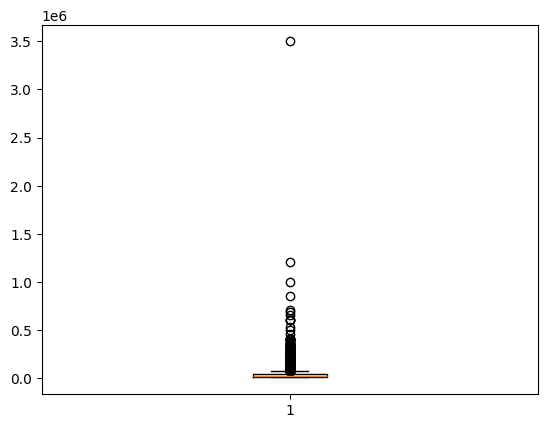

In [46]:
plt.boxplot(df['Rent'])
plt.show()

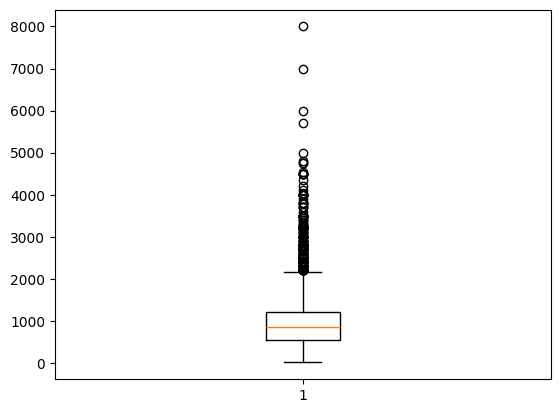

In [47]:
plt.boxplot(df['Size'])
plt.show()

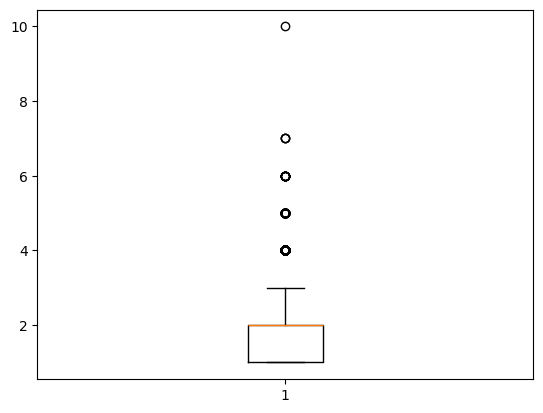

In [48]:
plt.boxplot(df['Bathroom'])
plt.show()

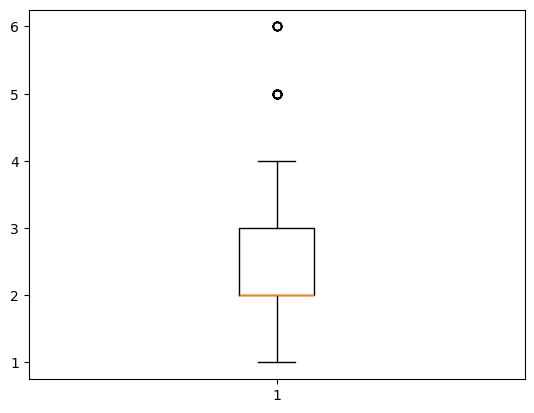

In [49]:
plt.boxplot(df['BHK'])
plt.show()

In [50]:
# outlier_col = ['Size','Bathroom','BHK']
# for i in outlier_col:
#   Q1 = df[i].quantile(0.25)
#   Q3 = df[i].quantile(0.75)
#   IQR = Q3-Q1
#   min = Q1-1.5*IQR
#   max = Q3+1.5*IQR
#   df[i] = df[i].clip(min,max)

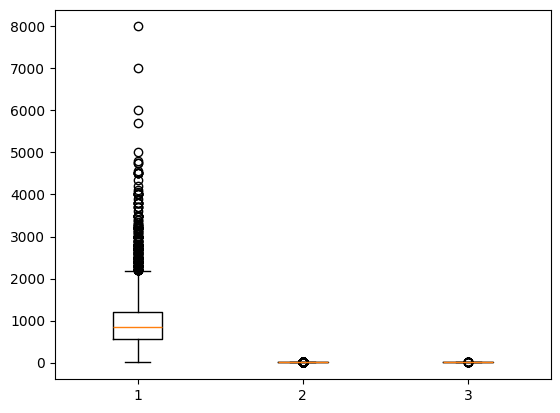

In [51]:
plt.boxplot(df[['Size','Bathroom','BHK']])
plt.show()

In [52]:
y=df['Rent']
Q1 = y.quantile(0.25)
Q3 = y.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = y[(y < lower) | (y > upper)]

In [53]:
len(outliers)

520

In [54]:
print(outliers)

104     180000.0
525      70000.0
527      75000.0
530     160000.0
531     300000.0
          ...   
4523     70000.0
4543    200000.0
4648     80000.0
4669    140000.0
4716    110000.0
Name: Rent, Length: 520, dtype: float64


In [55]:
# y = np.log1p(df['Rent'])

In [56]:
X=df.drop('Rent',axis=1)
y=df['Rent']

In [57]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.1,random_state=42,stratify=None)

print(X_train.shape,'        ',y_train.shape)
print(X_test.shape,'        ',y_test.shape)



(4271, 18)          (4271,)
(475, 18)          (475,)


In [58]:
col2 = ['City', 'Size', 'BHK']
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

X_train[col2] = sc.fit_transform(X_train[col2])
X_test[col2] = sc.transform(X_test[col2])

In [59]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train,y_train)

LinearRegression()

In [60]:
y_pred = model.predict(X_test)

In [61]:
y_pred[:5]

array([ 21384.05403368,  17496.57785698,  43698.3512867 ,  57324.16905647,
       137608.9571942 ])

In [62]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

mse = mean_squared_error(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print(mse)
print(mae)
print(r2)

3196753017.264253
24388.40678970131
0.4614555311747197


In [63]:
model.score(X_train,y_train)

0.30040819232063143

In [64]:
model.score(X_test,y_test)

0.4614555311747197

In [65]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [66]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [67]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }



  0%|          | 0/15 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.736e+12, tolerance: 2.612e+09
  model = cd_fast.enet_coordinate_descent(
100%|██████████| 15/15 [03:39<00:00, 14.65s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001841 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 737
[LightGBM] [Info] Number of data points in the train set: 4271, number of used features: 16
[LightGBM] [Info] Start training from score 34707.790583


In [68]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [69]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [70]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [71]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Stacking,4984.134023,11746.213930,2.265995e+09,1.754629e+09,47602.472374,41888.285980,0.629470,0.809300
CatBoost,7873.604384,11053.721104,2.794506e+08,1.321701e+09,16716.775752,36355.211186,0.954305,0.777338
GradientBoosting,7043.851912,10930.809790,1.937338e+08,1.466278e+09,13918.830075,38292.009615,0.968321,0.752982
HistGradientBoosting,6605.077114,10942.410236,1.517101e+09,1.533839e+09,38949.980463,39164.261849,0.751928,0.741600
AdaBoost,17639.695702,19173.430295,8.148787e+08,1.620355e+09,28546.080758,40253.632293,0.866753,0.727025
Bagging,4861.930494,10868.121852,6.018196e+08,1.620851e+09,24532.012456,40259.794617,0.901592,0.726942
XGBoost,4010.265811,10558.902446,4.290160e+07,1.649993e+09,6549.931092,40620.103256,0.992985,0.722032
ExtraTrees,16.135175,10842.507311,1.595338e+05,1.683482e+09,399.416768,41030.256563,0.999974,0.716390
Simple Voting,8204.277071,11746.213930,7.199307e+08,1.754629e+09,26831.524752,41888.285980,0.882279,0.712836
Voting,8204.277071,11746.213930,7.199307e+08,1.754629e+09,26831.524752,41888.285980,0.882279,0.712836


<Axes: >

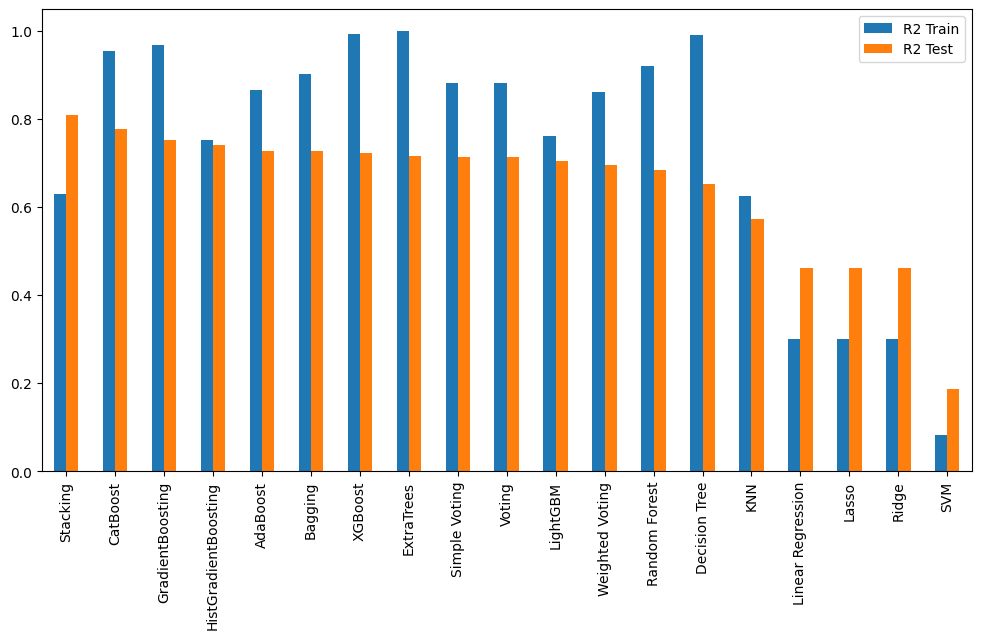

In [72]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

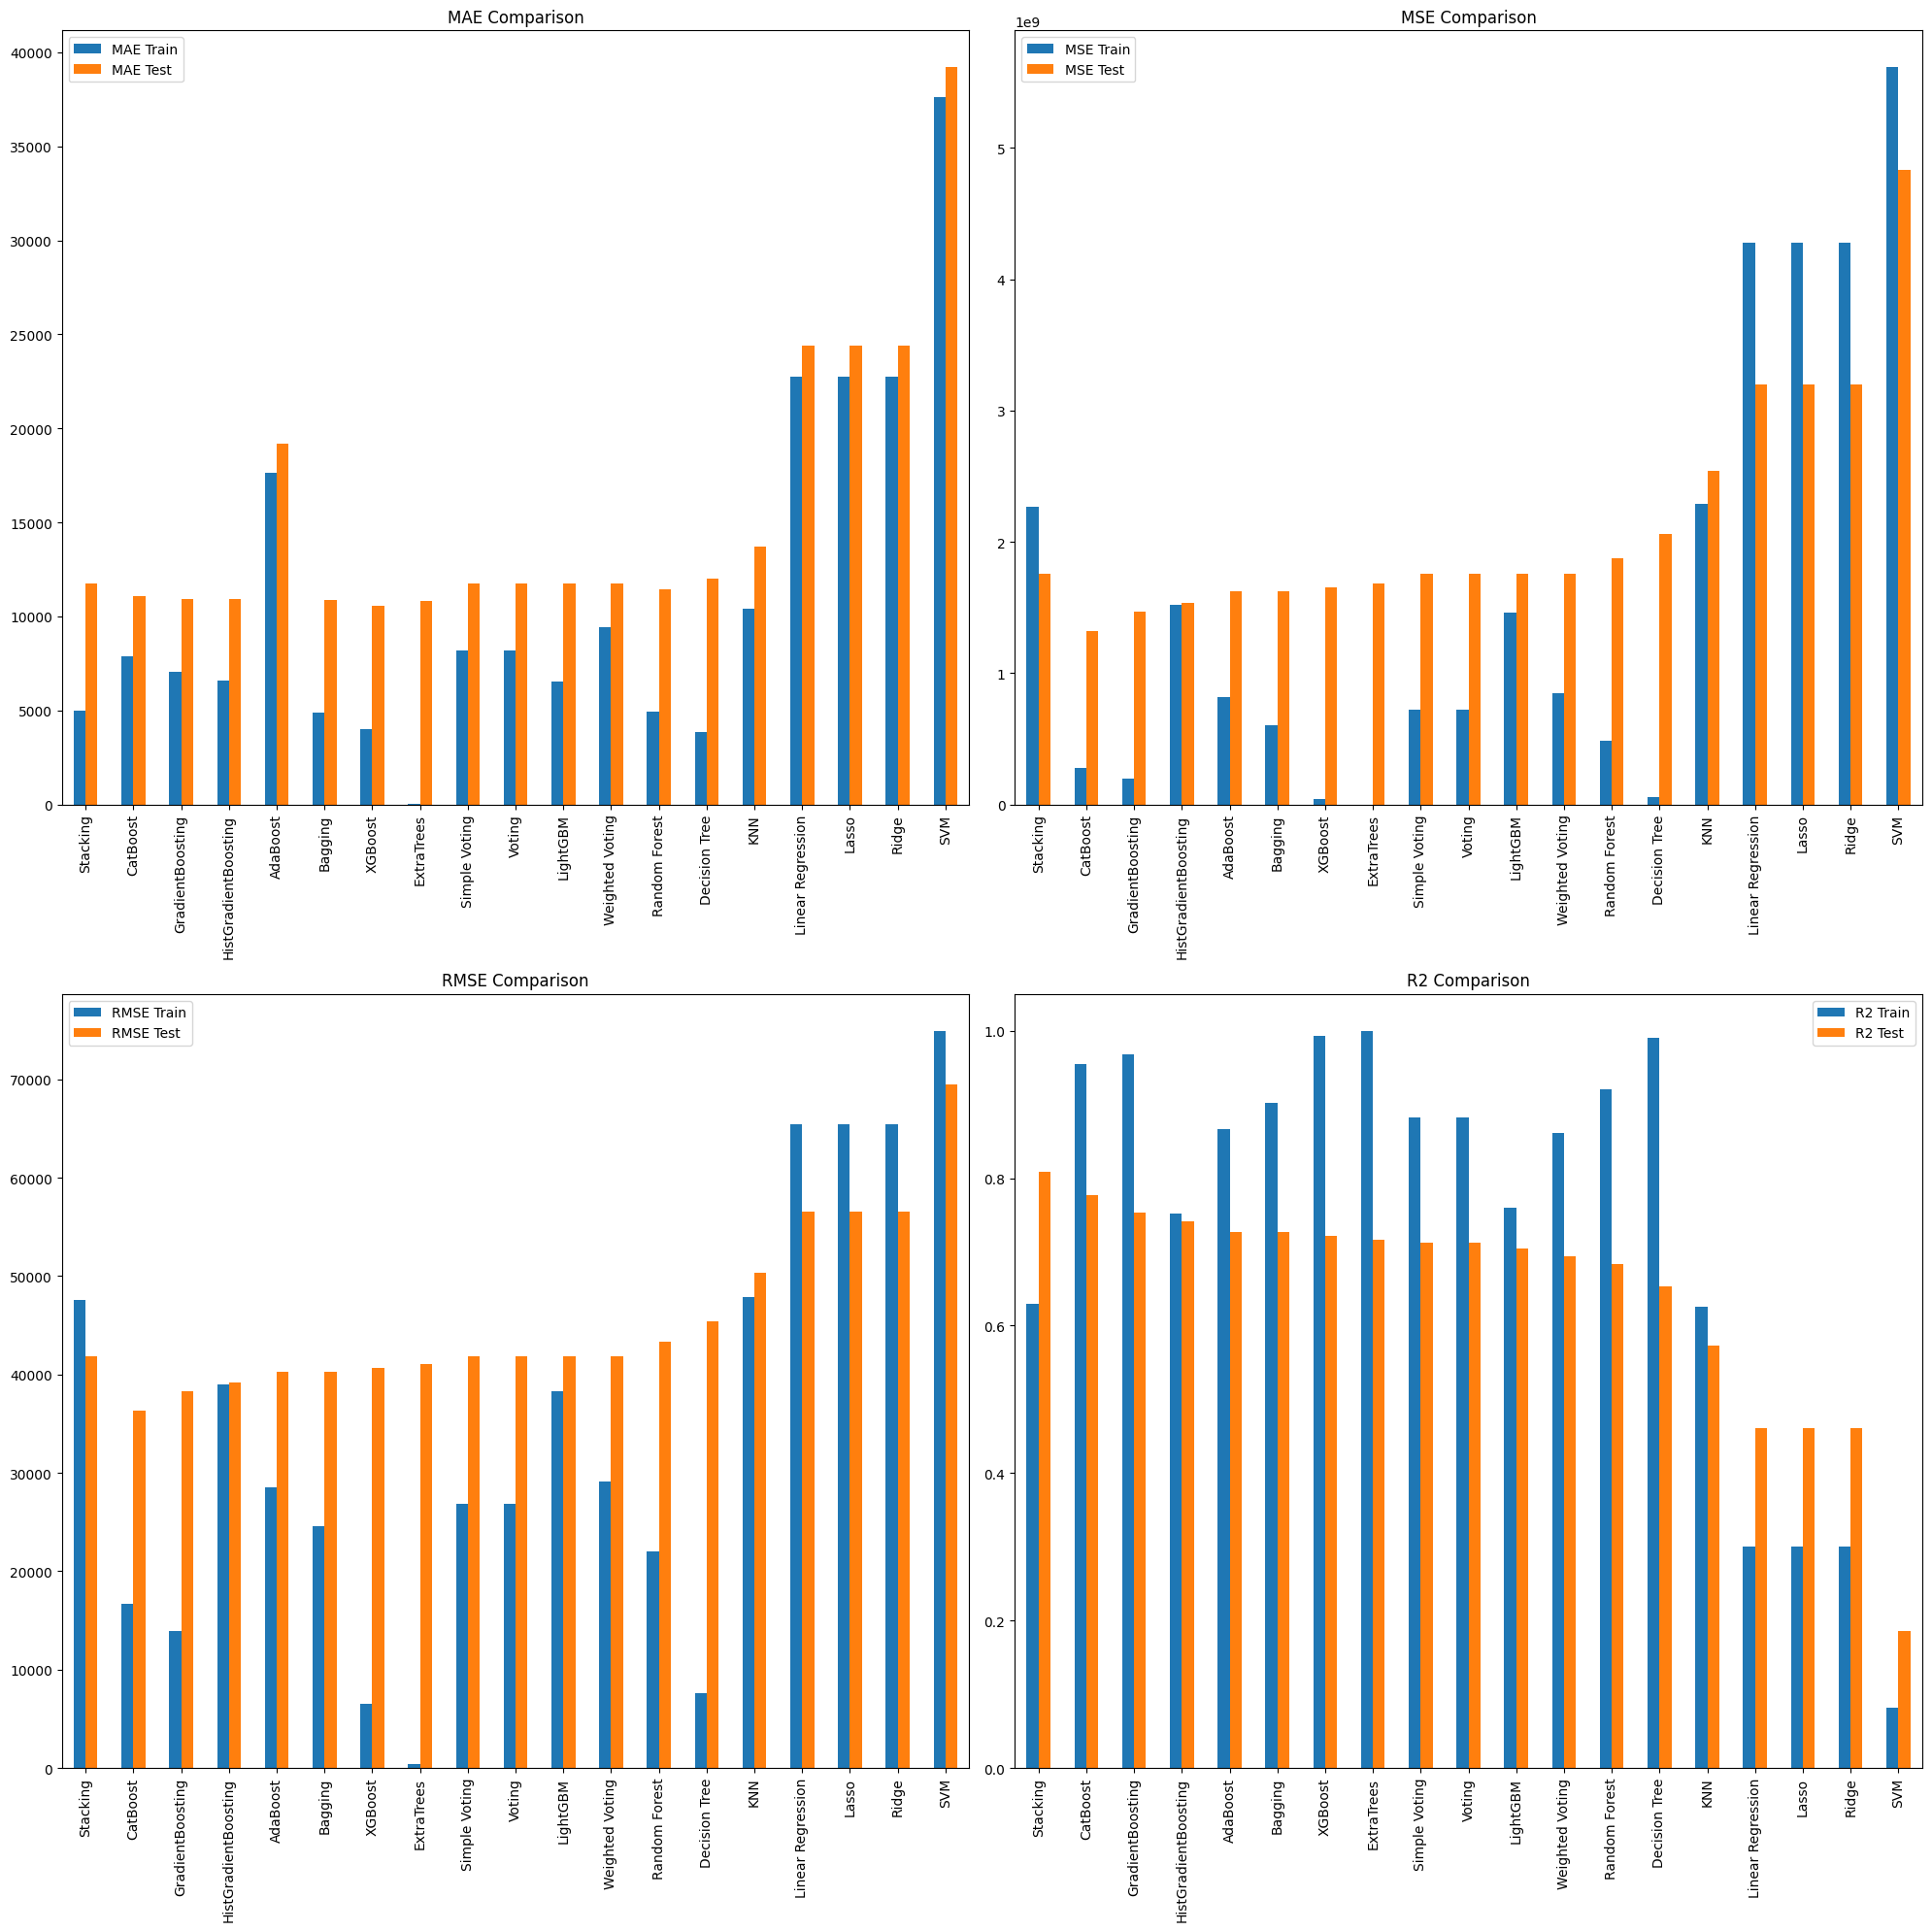

In [73]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()